# Zomato Exploratory Data Analysis Project

## Step 1 - Installing Matplotlib & Seaborn Library

In [1]:
import piplite
await piplite.install(['matplotlib', 'seaborn'])


## Step 2 - Importing all the required Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
%pip install seaborn

In [4]:
import piplite
await piplite.install('seaborn')

## Step 3 - Loading the Dataset

In [5]:
df = pd.read_csv("zomato_data.csv")

In [6]:
df.head(5)

,Restaurant Name,Online_Order,Book_Table,Rate,Votes,Approx_Cost(For Two People),Listed_In(Type)
0,Jalsa,Yes,Yes,4.1/5,775,800,Buffet
1,Spice Elephant,Yes,No,4.1/5,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8/5,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7/5,88,300,Buffet
4,Grand Village,No,No,3.8/5,166,600,Buffet


In [7]:
df.shape

(148, 7)

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   Restaurant Name              148 non-null    str  
 1   Online_Order                 148 non-null    str  
 2   Book_Table                   148 non-null    str  
 3   Rate                         148 non-null    str  
 4   Votes                        148 non-null    int64
 5   Approx_Cost(For Two People)  148 non-null    int64
 6   Listed_In(Type)              148 non-null    str  
dtypes: int64(2), str(5)
memory usage: 5.3 KB


In [9]:
df.describe(include='all')

,Restaurant Name,Online_Order,Book_Table,Rate,Votes,Approx_Cost(For Two People),Listed_In(Type)
count,148,148,148,148,148.000000,148.000000,148
unique,145,2,2,20,NaN,NaN,4
top,San Churro Cafe,No,No,3.8/5,NaN,NaN,Dining
freq,2,90,140,19,NaN,NaN,110
mean,NaN,NaN,NaN,NaN,264.810811,418.243243,NaN
std,NaN,NaN,NaN,NaN,653.676951,223.085098,NaN
min,NaN,NaN,NaN,NaN,0.000000,100.000000,NaN
25%,NaN,NaN,NaN,NaN,6.750000,200.000000,NaN
50%,NaN,NaN,NaN,NaN,43.500000,400.000000,NaN
75%,NaN,NaN,NaN,NaN,221.750000,600.000000,NaN


## Step 4 - Data Cleaning & Preparation

### 1. Convert the Rate Column to a Numeric Data Type

In [10]:
def handleRate(value):
    value = str(value).split('/')
    value = value[0]
    return float(value)
df['Rate'] = df['Rate'].apply(handleRate)
print(df.head(5))

         Restaurant Name Online_Order Book_Table  Rate  Votes  \
0                  Jalsa          Yes        Yes   4.1    775   
1         Spice Elephant          Yes         No   4.1    787   
2        San Churro Cafe          Yes         No   3.8    918   
3  Addhuri Udupi Bhojana           No         No   3.7     88   
4          Grand Village           No         No   3.8    166   

   Approx_Cost(For Two People) Listed_In(Type)  
0                          800          Buffet  
1                          800          Buffet  
2                          800          Buffet  
3                          300          Buffet  
4                          600          Buffet  


In [11]:
df. info()

<class 'pandas.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Restaurant Name              148 non-null    str    
 1   Online_Order                 148 non-null    str    
 2   Book_Table                   148 non-null    str    
 3   Rate                         148 non-null    float64
 4   Votes                        148 non-null    int64  
 5   Approx_Cost(For Two People)  148 non-null    int64  
 6   Listed_In(Type)              148 non-null    str    
dtypes: float64(1), int64(2), str(4)
memory usage: 5.9 KB


### 2. Standardize Column Names

In [12]:
df.columns = df.columns.str.lower()

In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   restaurant name              148 non-null    str    
 1   online_order                 148 non-null    str    
 2   book_table                   148 non-null    str    
 3   rate                         148 non-null    float64
 4   votes                        148 non-null    int64  
 5   approx_cost(for two people)  148 non-null    int64  
 6   listed_in(type)              148 non-null    str    
dtypes: float64(1), int64(2), str(4)
memory usage: 5.9 KB


In [14]:
df.columns

Index(['restaurant name', 'online_order', 'book_table', 'rate', 'votes',
       'approx_cost(for two people)', 'listed_in(type)'],
      dtype='str')

### Step 3 - Rename the Cost Column

In [15]:
df.rename(
    columns={'approx_cost(for two people)': 'approx_cost'},
    inplace=True
)

In [16]:
df.columns

Index(['restaurant name', 'online_order', 'book_table', 'rate', 'votes',
       'approx_cost', 'listed_in(type)'],
      dtype='str')

### Step 4 - Checking for Missing Values & Duplicate Records



In [17]:
print("Missing Values:")
print(df.isnull().sum())
print("Duplicate Rows:", df.duplicated().sum())

Missing Values:
restaurant name    0
online_order       0
book_table         0
rate               0
votes              0
approx_cost        0
listed_in(type)    0
dtype: int64
Duplicate Rows: 0


## Step 5 - Exploratory Data Analysis

# 1. How many customer votes has each restaurant type received?

In [18]:
df.head()

,restaurant name,online_order,book_table,rate,votes,approx_cost,listed_in(type)
0,Jalsa,Yes,Yes,4.1,775,800,Buffet
1,Spice Elephant,Yes,No,4.1,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7,88,300,Buffet
4,Grand Village,No,No,3.8,166,600,Buffet


In [19]:
grouped_data = df.groupby("listed_in(type)")["votes"].sum() 
grouped_data

listed_in(type)
Buffet     3028
Cafes      6434
Dining    20363
other      9367
Name: votes, dtype: int64

# 2. How many restaurants offer table booking?

In [20]:
result = df["book_table"].value_counts() 
result

book_table
No     140
Yes      8
Name: count, dtype: int64

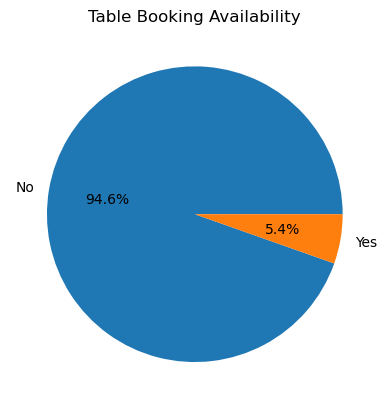

In [21]:
result.plot.pie(autopct="%1.1f%%") 
plt.title("Table Booking Availability") 
plt.show()

# 3. Which five restaurants have the highest number of votes?

In [22]:
top5 = df.nlargest(5, "votes") 
print(top5[["restaurant name", "votes"]]) 

      restaurant name  votes
38  Empire Restaurant   4884
86      Meghana Foods   4401
7              Onesta   2556
44             Onesta   2556
65        Kabab Magic   1720


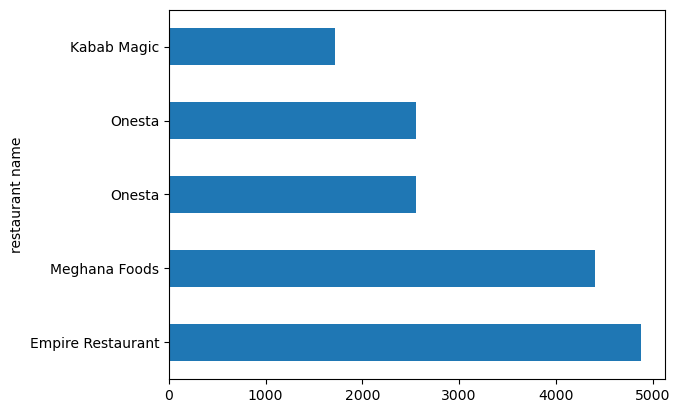

In [23]:
top5.plot.barh(x="restaurant name", y="votes", legend=False) 
plt.show()

# 4. Is there a relationship between restaurant ratings and customer votes? 


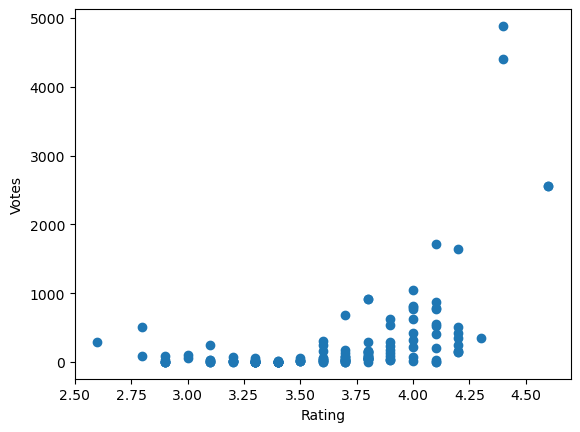

In [24]:
plt.scatter(df["rate"], df["votes"]) 
plt.xlabel("Rating") 
plt.ylabel("Votes") 
plt.show() 

# 5. What is the average rating for each restaurant type? 

In [25]:
result = df.groupby("listed_in(type)")["rate"].mean() 
print(result.sort_values(ascending=False)) 
 

listed_in(type)
other     3.912500
Buffet    3.842857
Cafes     3.765217
Dining    3.571818
Name: rate, dtype: float64


# 6. Which restaurant type is most common in the dataset? 

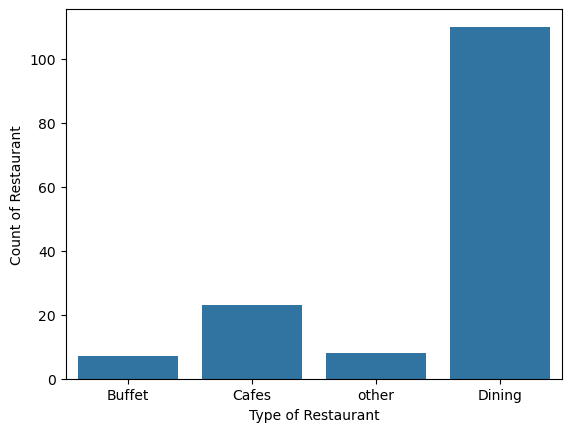

In [26]:
sns.countplot(x=df["listed_in(type)"]) 
plt.xlabel("Type of Restaurant") 
plt.ylabel("Count of Restaurant") 
plt.show()

# 7. What ratings do restaurants most commonly receive? 

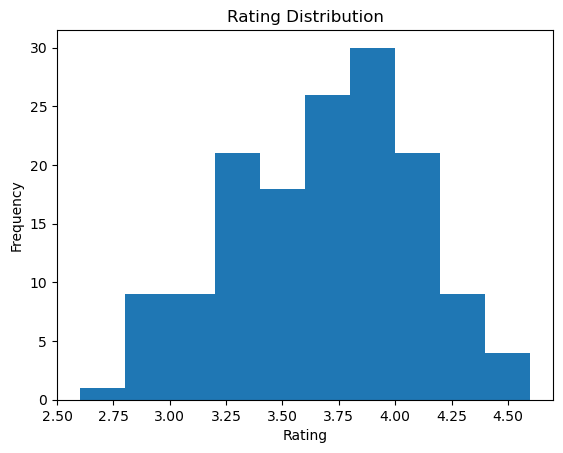

In [29]:
plt.hist(df["rate"], bins=10) 
plt.title("Rating Distribution") 
plt.xlabel("Rating") 
plt.ylabel("Frequency")
plt.show()

# 8. Which restaurant type has the highest average cost for two people?

In [30]:
result = df.groupby("listed_in(type)")["approx_cost"].mean() 
result.sort_values(ascending=False)

listed_in(type)
Buffet    671.428571
other     668.750000
Cafes     545.652174
Dining    357.272727
Name: approx_cost, dtype: float64

# 9. Do restaurants offering online ordering have higher ratings?

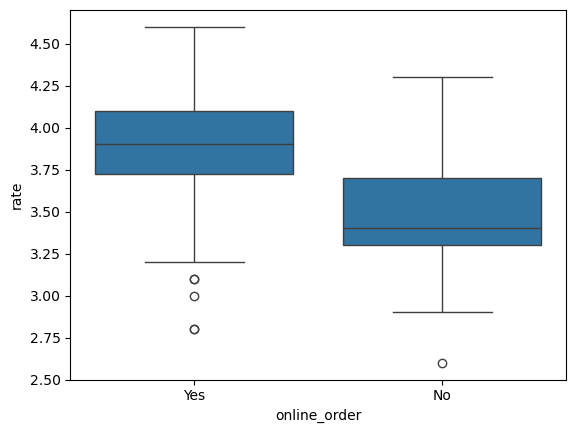

In [31]:
sns.boxplot(x="online_order", y="rate", data=df) 
plt.show()

# 10. Which restaurant types have more records without online ordering?

In [32]:
pivot_table = df.pivot_table( 
    index="listed_in(type)", 
    columns="online_order", 
    aggfunc="size", 
    fill_value=0 
) 
pivot_table 

online_order,No,Yes
listed_in(type),,
Buffet,3,4
Cafes,8,15
Dining,77,33
other,2,6


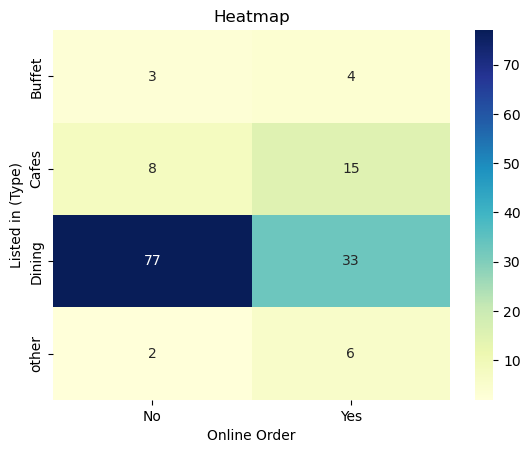

In [33]:

sns.heatmap(pivot_table, annot=True, cmap="YlGnBu", fmt="d") 
plt.title("Heatmap") 
plt.xlabel("Online Order") 
plt.ylabel("Listed in (Type)")
plt.show()